<a href="https://colab.research.google.com/github/mohammedshamilm7890/Women-s-E-Commerce-Clothing-Reviews/blob/main/Women%E2%80%99s_E_Commerce_Clothing_Reviews.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Women’s E-Commerce Clothing Reviews using NLP

In [ ]:
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
import matplotlib.pyplot as plt

In [ ]:
df=pd.read_csv('/content/archive.zip')
df

,Unnamed: 0,Clothing ID,Age,Title,Review Text,Rating,Recommended IND,Positive Feedback Count,Division Name,Department Name,Class Name
0,0,767,33,NaN,Absolutely wonderful - silky and sexy and comf...,4,1,0,Initmates,Intimate,Intimates
1,1,1080,34,NaN,Love this dress! it's sooo pretty. i happene...,5,1,4,General,Dresses,Dresses
2,2,1077,60,Some major design flaws,I had such high hopes for this dress and reall...,3,0,0,General,Dresses,Dresses
3,3,1049,50,My favorite buy!,"I love, love, love this jumpsuit. it's fun, fl...",5,1,0,General Petite,Bottoms,Pants
4,4,847,47,Flattering shirt,This shirt is very flattering to all due to th...,5,1,6,General,Tops,Blouses
...,...,...,...,...,...,...,...,...,...,...,...
23481,23481,1104,34,Great dress for many occasions,I was very happy to snag this dress at such a ...,5,1,0,General Petite,Dresses,Dresses
23482,23482,862,48,Wish it was made of cotton,"It reminds me of maternity clothes. soft, stre...",3,1,0,General Petite,Tops,Knits
23483,23483,1104,31,"Cute, but see through","This fit well, but the top was very see throug...",3,0,1,General Petite,Dresses,Dresses
23484,23484,1084,28,"Very cute dress, perfect for summer parties an...",I bought this dress for a wedding i have this ...,3,1,2,General,Dresses,Dresses


In [ ]:
print('Row count: ',df.shape[0])
print('Column count: ',df.shape[1])

Row count:  23486
Column count:  11


Handling the missing values.

In [ ]:
df.isnull().sum()

,0
Unnamed: 0,0
Clothing ID,0
Age,0
Title,3810
Review Text,845
Rating,0
Recommended IND,0
Positive Feedback Count,0
Division Name,14
Department Name,14


In [ ]:
# Percentage of missing values
missing = (df.isnull().sum() / len(df)) * 100
print(missing)

Unnamed: 0                  0.000000
Clothing ID                 0.000000
Age                         0.000000
Title                      16.222430
Review Text                 3.597888
Rating                      0.000000
Recommended IND             0.000000
Positive Feedback Count     0.000000
Division Name               0.059610
Department Name             0.059610
Class Name                  0.059610
dtype: float64


In [ ]:
# Remove rows where Review Text is missing
df = df.dropna(subset=['Review Text'])

In [ ]:
# Fill missing titles
df['Title'] = df['Title'].fillna('')

/tmp/ipykernel_569/1514153709.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['Title'] = df['Title'].fillna('')


In [ ]:
# Check again
df.isnull().sum()

,0
Unnamed: 0,0
Clothing ID,0
Age,0
Title,0
Review Text,0
Rating,0
Recommended IND,0
Positive Feedback Count,0
Division Name,13
Department Name,13


In [ ]:
# Remove rows with missing categorical values
df = df.dropna(subset=['Division Name', 'Department Name', 'Class Name'])

# Verify
print(df.isnull().sum())

Unnamed: 0                 0
Clothing ID                0
Age                        0
Title                      0
Review Text                0
Rating                     0
Recommended IND            0
Positive Feedback Count    0
Division Name              0
Department Name            0
Class Name                 0
dtype: int64


In [ ]:
df['Division Name'] = df['Division Name'].fillna('Unknown')
df['Department Name'] = df['Department Name'].fillna('Unknown')
df['Class Name'] = df['Class Name'].fillna('Unknown')

print(df.isnull().sum())

Unnamed: 0                 0
Clothing ID                0
Age                        0
Title                      0
Review Text                0
Rating                     0
Recommended IND            0
Positive Feedback Count    0
Division Name              0
Department Name            0
Class Name                 0
dtype: int64


In [ ]:
for col in ['Division Name', 'Department Name', 'Class Name']:
    df[col] = df[col].fillna(df[col].mode()[0])

print(df.isnull().sum())

Unnamed: 0                 0
Clothing ID                0
Age                        0
Title                      0
Review Text                0
Rating                     0
Recommended IND            0
Positive Feedback Count    0
Division Name              0
Department Name            0
Class Name                 0
dtype: int64


In [ ]:
print("Dataset Shape:", df.shape)

Dataset Shape: (22628, 11)


Exploratory Data Analysis

In [ ]:
df['Rating'].value_counts().sort_index()

,count
Rating,
1,821
2,1549
3,2823
4,4908
5,12527


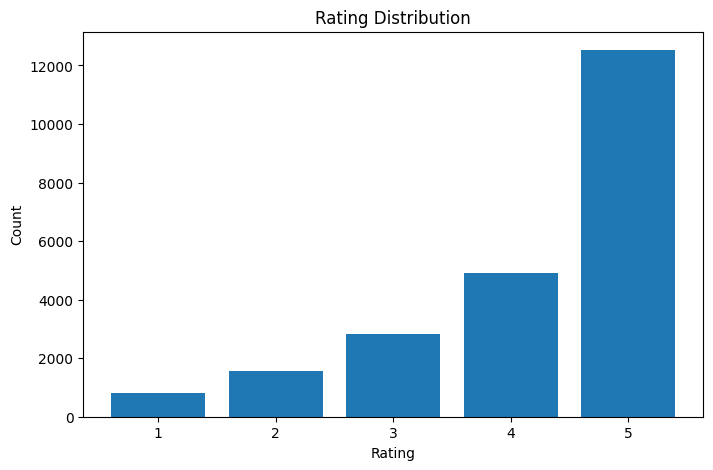

In [ ]:
rating=df['Rating'].value_counts().sort_index()

plt.figure(figsize=(8,5))

plt.bar(rating.index,rating.values)

plt.title("Rating Distribution")

plt.xlabel("Rating")

plt.ylabel("Count")

plt.show()

Recommendation Distribution

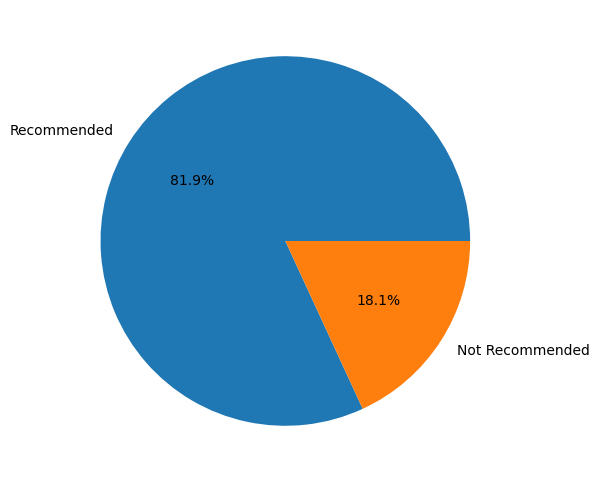

In [ ]:
recommend=df['Recommended IND'].value_counts()

plt.figure(figsize=(6,6))

plt.pie(
recommend,
labels=['Recommended','Not Recommended'],
autopct='%1.1f%%'
)

plt.show()

Department Distribution

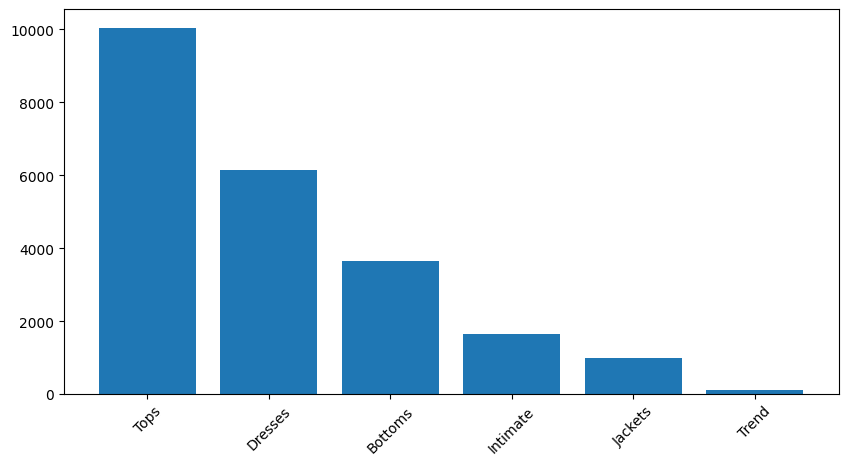

In [ ]:
dept=df['Department Name'].value_counts()

plt.figure(figsize=(10,5))

plt.bar(dept.index,dept.values)

plt.xticks(rotation=45)

plt.show()

age

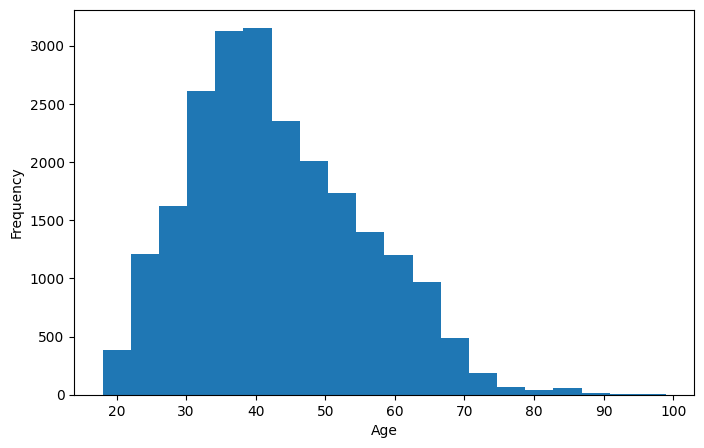

In [ ]:
plt.figure(figsize=(8,5))

plt.hist(df['Age'],bins=20)

plt.xlabel("Age")

plt.ylabel("Frequency")

plt.show()

Review Length

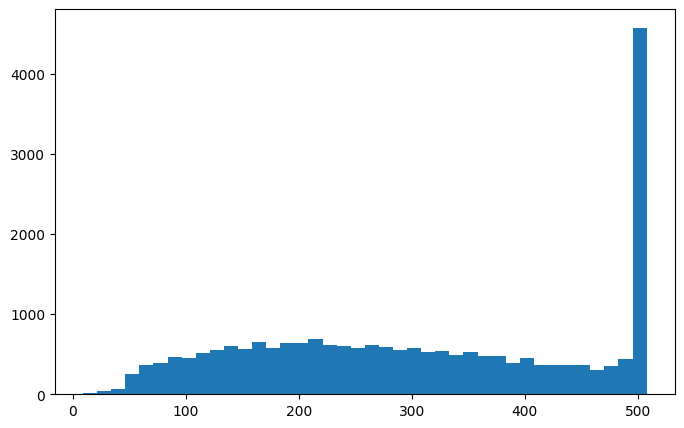

In [ ]:
df['Review_Length']=df['Review Text'].apply(len)

plt.figure(figsize=(8,5))

plt.hist(df['Review_Length'],bins=40)

plt.show()

Create Sentiment

In [ ]:
df['Sentiment']=df['Rating'].apply(lambda x:1 if x>=4 else 0)

df[['Rating','Sentiment']].head()

,Rating,Sentiment
0,4,1
1,5,1
2,3,0
3,5,1
4,5,1


In [ ]:
import nltk

nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


True

In [ ]:
import re
import string

from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

In [ ]:
stop_words = set(stopwords.words('english'))

lemmatizer = WordNetLemmatizer()

In [ ]:
def clean_text(text):

    # Convert to lowercase
    text = text.lower()

    # Remove numbers
    text = re.sub(r'\d+', '', text)

    # Remove punctuation
    text = text.translate(str.maketrans('', '', string.punctuation))

    # Remove extra spaces
    text = text.strip()

    # Tokenization
    words = text.split()

    # Remove stopwords
    words = [word for word in words if word not in stop_words]

    # Lemmatization
    words = [lemmatizer.lemmatize(word) for word in words]

    # Join words
    text = " ".join(words)

    return text

In [ ]:
df['Clean_Review'] = df['Review Text'].apply(clean_text)

In [ ]:
df[['Review Text','Clean_Review']].head(10)

,Review Text,Clean_Review
0,Absolutely wonderful - silky and sexy and comf...,absolutely wonderful silky sexy comfortable
1,Love this dress! it's sooo pretty. i happene...,love dress sooo pretty happened find store im ...
2,I had such high hopes for this dress and reall...,high hope dress really wanted work initially o...
3,"I love, love, love this jumpsuit. it's fun, fl...",love love love jumpsuit fun flirty fabulous ev...
4,This shirt is very flattering to all due to th...,shirt flattering due adjustable front tie perf...
5,"I love tracy reese dresses, but this one is no...",love tracy reese dress one petite foot tall us...
6,I aded this in my basket at hte last mintue to...,aded basket hte last mintue see would look lik...
7,"I ordered this in carbon for store pick up, an...",ordered carbon store pick ton stuff always try...
8,I love this dress. i usually get an xs but it ...,love dress usually get x run little snug bust ...
9,"I'm 5""5' and 125 lbs. i ordered the s petite t...",im lb ordered petite make sure length wasnt lo...


In [ ]:
print(df['Clean_Review'].isnull().sum())

0


In [ ]:
for i in range(5):
    print("Original Review:")
    print(df['Review Text'][i])

    print("\nClean Review:")
    print(df['Clean_Review'][i])

    print("-"*80)

Original Review:
Absolutely wonderful - silky and sexy and comfortable

Clean Review:
absolutely wonderful silky sexy comfortable
--------------------------------------------------------------------------------
Original Review:
Love this dress!  it's sooo pretty.  i happened to find it in a store, and i'm glad i did bc i never would have ordered it online bc it's petite.  i bought a petite and am 5'8".  i love the length on me- hits just a little below the knee.  would definitely be a true midi on someone who is truly petite.

Clean Review:
love dress sooo pretty happened find store im glad bc never would ordered online bc petite bought petite love length hit little knee would definitely true midi someone truly petite
--------------------------------------------------------------------------------
Original Review:
I had such high hopes for this dress and really wanted it to work for me. i initially ordered the petite small (my usual size) but i found this to be outrageously small. so s

In [ ]:
df.to_csv("cleaned_reviews.csv", index=False)

Vectorization

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

In [ ]:
df['Clean_Review'].head()

,Clean_Review
0,absolutely wonderful silky sexy comfortable
1,love dress sooo pretty happened find store im ...
2,high hope dress really wanted work initially o...
3,love love love jumpsuit fun flirty fabulous ev...
4,shirt flattering due adjustable front tie perf...


In [ ]:
X = df['Clean_Review']

y = df['Sentiment']

In [ ]:
tfidf = TfidfVectorizer(max_features=5000)

In [ ]:
X = tfidf.fit_transform(X)

In [ ]:
print(X.shape)

(22628, 5000)


In [ ]:
print(tfidf.get_feature_names_out()[:20])

['aa' 'ab' 'abby' 'abdomen' 'ability' 'able' 'abo' 'absolute' 'absolutely'
 'absolutley' 'abstract' 'absurd' 'abt' 'abundance' 'ac' 'accent'
 'accented' 'accentuate' 'accentuated' 'accentuates']
